# **Case Study 2 — E-Commerce Sales & Customer Analytics**                                                          
**Phase D: Python / Pandas Analysis**                                                                                                             
This notebook loads the raw data files, independently inspects and cleans them using Python (Pandas/NumPy), merges the datasets, and produces the required descriptive statistics, groupby analysis, and visualizations.

Data files: `customers.csv`, `products.csv`, `orders.csv`, `locations.csv`

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

• Load all datasets, inspect their structure, and produce a missing-value and duplicate-value summary.                       
• Clean categorical/text inconsistencies and convert date columns to appropriate date types.                                                  
• Merge the datasets where required.                                                                                               
• Generate descriptive statistics and investigate outliers in sales, quantity and discounts.                                                  
• Perform groupby analysis by product, category, customer and location.                                            
• Analyze relationships between important numerical variables.                                                                 

**Load the Dataset**

In [3]:
customers=pd.read_csv(r"C:\Users\jinoj\OneDrive\Desktop\Nest Internship\Dataset\customers.csv")
locations=pd.read_csv(r"C:\Users\jinoj\OneDrive\Desktop\Nest Internship\Dataset\locations.csv")
orders=pd.read_csv(r"C:\Users\jinoj\OneDrive\Desktop\Nest Internship\Dataset\orders.csv")
products=pd.read_csv(r"C:\Users\jinoj\OneDrive\Desktop\Nest Internship\Dataset\products.csv")
display(customers,locations,orders,products)

,Customer_ID,Age,Gender,City,Signup_Date,Customer_Segment
0,C00001,39,Female,Bengaluru,2025-02-19,Premium
1,C00002,53,Male,Pune,2023-10-12,Regular
2,C00003,27,Male,Hyderabad,2023-02-09,New
3,C00004,45,Male,Delhi,2023-09-08,New
4,C00005,19,Male,Bengaluru,2025-06-05,New
...,...,...,...,...,...,...
4005,C03497,37,Male,Chennai,2024-09-16,Regular
4006,C02590,48,Male,Chennai,2023-03-03,New
4007,C00306,47,Female,Kolkata,2023-12-26,Regular
4008,C01691,63,Female,Pune,2023-03-29,Regular


,Location_ID,City,State,Region,Market_Size
0,L001,Bengaluru,Karnataka,East,Medium
1,L002,Mumbai,Maharashtra,West,High
2,L003,Delhi,Delhi,South,High
3,L004,Hyderabad,Telangana,West,High
4,L005,Chennai,Tamil Nadu,West,Medium
5,L006,Pune,Maharashtra,West,Low
6,L007,Kochi,Kerala,West,Medium
7,L008,Kolkata,West Bengal,East,Medium


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Order_Status,Payment_Method,Net_Sales
0,O000001,C03686,P0016,Bengaluru,2025-12-08,2,1858.0,278.70,0,Completed,Card,1579.30
1,O000002,C01521,P0026,Chennai,2025-04-15,2,1584.0,316.80,100,Completed,Cash on Delivery,1367.20
2,O000003,C01070,P0003,Delhi,2025-03-19,1,3441.0,688.20,100,Completed,Card,2852.80
3,O000004,C01785,P0028,Mumbai,2025-09-20,4,9396.0,1409.40,100,Completed,UPI,8086.60
4,O000005,C02669,P0008,Hyderabad,2025-05-21,3,14181.0,1418.10,0,Completed,Card,12762.90
...,...,...,...,...,...,...,...,...,...,...,...,...
18015,O006909,C02283,P0024,Delhi,2025-01-29,3,8742.0,1311.30,40,Completed,Card,7470.70
18016,O010926,C03903,P0025,Kolkata,2025-07-27,1,2832.0,283.20,100,Completed,Cash on Delivery,2648.80
18017,O011636,C02819,P0011,Hyderabad,2025-05-23,2,8520.0,2556.00,0,Completed,Cash on Delivery,5964.00
18018,O015752,C03979,P0016,Kolkata,2025-08-10,3,2787.0,418.05,100,Completed,Cash on Delivery,2468.95


,Product_ID,Product_Name,Category,Unit_Price,In_Stock
0,P0001,Wireless Earbuds,Electronics,-50.0,No
1,P0002,Smart Watch,Electronics,2787.0,Yes
2,P0003,Bluetooth Speaker,Electronics,-50.0,Yes
3,P0004,Power Bank,Electronics,2827.0,No
4,P0005,Keyboard,Electronics,4253.0,Yes
5,P0006,Mouse,Electronics,3248.0,Yes
6,P0007,T-Shirt,Fashion,4860.0,No
7,P0008,Jeans,Fashion,-50.0,Yes
8,P0009,Sneakers,Fashion,3170.0,Yes
9,P0010,Handbag,Fashion,-50.0,No


**Concise summary of the dataset**

In [4]:
#Shape and data types
for name, df in [("customers", customers), ("locations", locations),
                  ("orders", orders), ("products", products)]:
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print(df.dtypes)
    print()

--- customers ---
shape: (4010, 6)
Customer_ID         object
Age                  int64
Gender              object
City                object
Signup_Date         object
Customer_Segment    object
dtype: object

--- locations ---
shape: (8, 5)
Location_ID    object
City           object
State          object
Region         object
Market_Size    object
dtype: object

--- orders ---
shape: (18020, 12)
Order_ID           object
Customer_ID        object
Product_ID         object
City               object
Order_Date         object
Quantity            int64
Gross_Amount      float64
Discount          float64
Shipping_Fee        int64
Order_Status       object
Payment_Method     object
Net_Sales         float64
dtype: object

--- products ---
shape: (30, 5)
Product_ID       object
Product_Name     object
Category         object
Unit_Price      float64
In_Stock         object
dtype: object



In [5]:
#Non-null values
for i, df in enumerate([customers, locations, orders, products], 1):
    print(f"\n===== DATASET {i} =====")
    df.info()


===== DATASET 1 =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Customer_ID       4010 non-null   object
 1   Age               4010 non-null   int64 
 2   Gender            4010 non-null   object
 3   City              4010 non-null   object
 4   Signup_Date       4010 non-null   object
 5   Customer_Segment  4010 non-null   object
dtypes: int64(1), object(5)
memory usage: 188.1+ KB

===== DATASET 2 =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Location_ID  8 non-null      object
 1   City         8 non-null      object
 2   State        8 non-null      object
 3   Region       8 non-null      object
 4   Market_Size  8 non-null      object
dtypes: object(5)
memory usage: 452.0+ by

**Missing-value and duplicate-value summary**

In [6]:
print("MISSING VALUES\n")
for name, df in [("customers", customers), ("locations", locations),
                  ("orders", orders), ("products", products)]:
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    print(f"{name}: {dict(nulls)}" if len(nulls) else f"{name}: no missing values")

print("\nDUPLICATE ROWS\n")
for name, df in [("customers", customers), ("locations", locations),
                  ("orders", orders), ("products", products)]:
    print(f"{name}: {df.duplicated().sum()} exact duplicate rows")

MISSING VALUES

customers: no missing values
locations: no missing values
orders: {'Net_Sales': np.int64(25)}
products: no missing values

DUPLICATE ROWS

customers: 10 exact duplicate rows
locations: 0 exact duplicate rows
orders: 20 exact duplicate rows
products: 0 exact duplicate rows


**Data Cleaning**                                                                                                              
**(i) Removing Duplicates**

In [7]:
before_c, before_o = len(customers), len(orders)
customers = customers.drop_duplicates()
orders = orders.drop_duplicates()
print(f"customers: removed {before_c - len(customers)} duplicate rows")
print(f"orders: removed {before_o - len(orders)} duplicate rows")

customers: removed 10 duplicate rows
orders: removed 20 duplicate rows


**(ii) Fixing inconsistent categorical or text values**

In [8]:
#Column names
for i, df in enumerate([customers, locations, orders, products], 1):
    print(f"\n===== TABLE {i} =====")
    print(df.columns.tolist())


===== TABLE 1 =====
['Customer_ID', 'Age', 'Gender', 'City', 'Signup_Date', 'Customer_Segment']

===== TABLE 2 =====
['Location_ID', 'City', 'State', 'Region', 'Market_Size']

===== TABLE 3 =====
['Order_ID', 'Customer_ID', 'Product_ID', 'City', 'Order_Date', 'Quantity', 'Gross_Amount', 'Discount', 'Shipping_Fee', 'Order_Status', 'Payment_Method', 'Net_Sales']

===== TABLE 4 =====
['Product_ID', 'Product_Name', 'Category', 'Unit_Price', 'In_Stock']


In [9]:
#List the unique values in categorical columns
#customers
columns = ['Gender', 'City', 'Customer_Segment']

for col in columns:
    print(f"\n{col}")
    print("Number of unique values:", customers[col].nunique())
    print("Unique values:", customers[col].unique())


Gender
Number of unique values: 3
Unique values: ['Female' 'Male' 'Other']

City
Number of unique values: 8
Unique values: ['Bengaluru' 'Pune' 'Hyderabad' 'Delhi' 'Kolkata' 'Kochi' 'Mumbai'
 'Chennai']

Customer_Segment
Number of unique values: 4
Unique values: ['Premium' 'Regular' 'New' 'regular']


In [10]:
#Fixing inconsistent categorical or text values
customers['Customer_Segment'] = customers['Customer_Segment'].str.title()
print(customers['Customer_Segment'].unique())

['Premium' 'Regular' 'New']


In [11]:
#locations
columns = ['City', 'State', 'Region', 'Market_Size']

for col in columns:
    print(f"\n{col}:")
    print("Number of unique values:", locations[col].nunique())
    print("Unique values:", locations[col].unique())


City:
Number of unique values: 8
Unique values: ['Bengaluru' 'Mumbai' 'Delhi' 'Hyderabad' 'Chennai' 'Pune' 'Kochi'
 'Kolkata']

State:
Number of unique values: 7
Unique values: ['Karnataka' 'Maharashtra' 'Delhi' 'Telangana' 'Tamil Nadu' 'Kerala'
 'West Bengal']

Region:
Number of unique values: 3
Unique values: ['East' 'West' 'South']

Market_Size:
Number of unique values: 3
Unique values: ['Medium' 'High' 'Low']


In [12]:
#orders
columns = ['City', 'Order_Status', 'Payment_Method']

for col in columns:
    print(f"\n{col}:")
    print("Number of unique values:", orders[col].nunique())
    print("Unique values:", orders[col].unique())


City:
Number of unique values: 8
Unique values: ['Bengaluru' 'Chennai' 'Delhi' 'Mumbai' 'Hyderabad' 'Pune' 'Kochi'
 'Kolkata']

Order_Status:
Number of unique values: 4
Unique values: ['Completed' 'Returned' 'completed' 'Cancelled']

Payment_Method:
Number of unique values: 4
Unique values: ['Card' 'Cash on Delivery' 'UPI' 'Wallet']


In [13]:
#Fixing inconsistent categorical or text values
orders['Order_Status'] = orders['Order_Status'].str.title()
print(orders['Order_Status'].unique())

['Completed' 'Returned' 'Cancelled']


In [14]:
#products
columns = ['Product_Name', 'Category', 'In_Stock']

for col in columns:
    print(f"\n{col}:")
    print("Number of unique values:", products[col].nunique())
    print("Unique values:", products[col].unique())


Product_Name:
Number of unique values: 30
Unique values: ['Wireless Earbuds' 'Smart Watch' 'Bluetooth Speaker' 'Power Bank'
 'Keyboard' 'Mouse' 'T-Shirt' 'Jeans' 'Sneakers' 'Handbag' 'Jacket'
 'Sunglasses' 'Mixer Grinder' 'Cookware Set' 'Bedsheet' 'Storage Box'
 'Water Bottle' 'Coffee Maker' 'Face Wash' 'Moisturizer' 'Shampoo'
 'Perfume' 'Lipstick' 'Hair Dryer' 'Yoga Mat' 'Cricket Bat' 'Football'
 'Dumbbells' 'Running Shoes' 'Sports Bag']

Category:
Number of unique values: 5
Unique values: ['Electronics' 'Fashion' 'Home & Kitchen' 'Beauty' 'Sports']

In_Stock:
Number of unique values: 2
Unique values: ['No' 'Yes']


**(iii) Converting date columns datatype to datetime**

In [15]:
customers['Signup_Date'] = pd.to_datetime(customers['Signup_Date'])
orders['Order_Date'] = pd.to_datetime(orders['Order_Date'])
print(orders['Order_Date'].dtype, customers['Signup_Date'].dtype)
print("Signup_Date range:", customers['Signup_Date'].min(), "to", customers['Signup_Date'].max())
print("Order_Date range:", orders['Order_Date'].min(), "to", orders['Order_Date'].max())

datetime64[ns] datetime64[ns]
Signup_Date range: 2023-01-01 00:00:00 to 2025-09-26 00:00:00
Order_Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


**(iv) Fixing invalid numeric values**

In [16]:
#To check negative values in products table
products[products['Unit_Price'] < 0]

,Product_ID,Product_Name,Category,Unit_Price,In_Stock
0,P0001,Wireless Earbuds,Electronics,-50.0,No
2,P0003,Bluetooth Speaker,Electronics,-50.0,Yes
7,P0008,Jeans,Fashion,-50.0,Yes
9,P0010,Handbag,Fashion,-50.0,No
15,P0016,Storage Box,Home & Kitchen,-50.0,Yes


In [17]:
products['Unit_Price'] = products['Unit_Price'].abs()
#check
print(products['Unit_Price'].min())

50.0


**(v) Fixing missing values**

In [18]:
#Already found missing values in orders table in Net_Sales column
print(orders['Net_Sales'].isna().sum())

25


In [19]:
#Fixing the missing values
#Net_Sales = Gross_Amount - Discount + Shipping_Fee
orders['Net_Sales'] = orders['Net_Sales'].fillna(
    orders['Gross_Amount'] - orders['Discount'] + orders['Shipping_Fee']
)
#check
print(orders['Net_Sales'].isna().sum())


0


**(v) Descriptive Statistics**

In [20]:
print("===== CUSTOMERS =====")
display(customers.describe())

print("===== LOCATIONS =====")
display(locations.describe())

print("===== ORDERS =====")
display(orders.describe())

print("===== PRODUCTS =====")
display(products.describe())

===== CUSTOMERS =====


,Age,Signup_Date
count,4000.000000,4000
mean,40.548750,2024-05-15 07:37:12
min,18.000000,2023-01-01 00:00:00
25%,29.000000,2023-09-06 00:00:00
50%,40.000000,2024-05-11 00:00:00
75%,52.000000,2025-01-23 00:00:00
max,64.000000,2025-09-26 00:00:00
std,13.540973,NaN


===== LOCATIONS =====


,Location_ID,City,State,Region,Market_Size
count,8,8,8,8,8
unique,8,8,7,3,3
top,L001,Bengaluru,Maharashtra,West,Medium
freq,1,1,2,5,4


===== ORDERS =====


,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Net_Sales
count,18000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000
mean,2025-07-02 05:42:57.600000256,1.804500,6028.777778,504.189025,56.042222,5580.630975
min,2025-01-01 00:00:00,1.000000,792.000000,0.000000,0.000000,554.400000
25%,2025-04-02 00:00:00,1.000000,3120.000000,0.000000,40.000000,2927.000000
50%,2025-07-03 00:00:00,1.000000,4722.000000,283.200000,60.000000,4343.000000
75%,2025-09-30 00:00:00,2.000000,8506.000000,709.050000,80.000000,7577.600000
max,2025-12-31 00:00:00,5.000000,24320.000000,7296.000000,100.000000,24420.000000
std,NaN,1.002664,4091.399262,703.105764,34.300651,3782.884112


===== PRODUCTS =====


,Unit_Price
count,30.000000
mean,2844.100000
std,1613.782713
min,50.000000
25%,2178.250000
50%,3029.500000
75%,4258.250000
max,4864.000000


**(vi) Investigation on outliers in sales, quantity and discounts**

In [21]:
#Check outliers in all 3 columns
columns = ['Net_Sales', 'Quantity', 'Discount']

for col in columns:
    Q1 = orders[col].quantile(0.25)
    Q3 = orders[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = orders[(orders[col] < lower) | (orders[col] > upper)]

    print(f"\n===== {col} =====")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))


===== Net_Sales =====
Lower limit: -4048.9000000000005
Upper limit: 14553.5
Number of outliers: 630

===== Quantity =====
Lower limit: -0.5
Upper limit: 3.5
Number of outliers: 1379

===== Discount =====
Lower limit: -1063.5749999999998
Upper limit: 1772.6249999999998
Number of outliers: 993


In [22]:
#To see the actual outlier rows
columns = ['Net_Sales', 'Quantity', 'Discount']

for col in columns:
    Q1 = orders[col].quantile(0.25)
    Q3 = orders[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = orders[(orders[col] < lower) | (orders[col] > upper)]

    print(f"\n===== Outliers in {col} =====")
    display(outliers)


===== Outliers in Net_Sales =====


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Order_Status,Payment_Method,Net_Sales
10,O000011,C01944,P0011,Chennai,2025-01-26,4,17040.0,1704.0,40,Returned,UPI,15376.0
28,O000029,C03181,P0021,Delhi,2025-10-12,4,19456.0,2918.4,100,Completed,Cash on Delivery,16637.6
58,O000059,C02099,P0008,Pune,2025-06-27,4,18908.0,2836.2,0,Completed,UPI,16071.8
105,O000106,C02515,P0008,Hyderabad,2025-07-23,5,23635.0,0.0,40,Completed,Card,23675.0
111,O000112,C02100,P0011,Hyderabad,2025-06-27,5,21300.0,0.0,40,Completed,Card,21340.0
...,...,...,...,...,...,...,...,...,...,...,...,...
17893,O017894,C00994,P0018,Delhi,2025-09-12,5,23610.0,1180.5,100,Completed,Card,22529.5
17919,O017920,C00494,P0007,Mumbai,2025-12-03,4,19440.0,2916.0,100,Cancelled,Wallet,16624.0
17920,O017921,C03317,P0014,Bengaluru,2025-04-14,4,17372.0,0.0,80,Completed,Wallet,17452.0
17961,O017962,C00833,P0027,Kochi,2025-05-16,5,23880.0,2388.0,80,Completed,Cash on Delivery,21572.0



===== Outliers in Quantity =====


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Order_Status,Payment_Method,Net_Sales
3,O000004,C01785,P0028,Mumbai,2025-09-20,4,9396.0,1409.4,100,Completed,UPI,8086.6
10,O000011,C01944,P0011,Chennai,2025-01-26,4,17040.0,1704.0,40,Returned,UPI,15376.0
14,O000015,C03426,P0013,Pune,2025-09-08,4,17156.0,3431.2,40,Completed,Card,13764.8
16,O000017,C00503,P0023,Mumbai,2025-08-09,4,11896.0,1784.4,0,Completed,UPI,10111.6
22,O000023,C02414,P0012,Kochi,2025-06-28,4,15400.0,1540.0,0,Completed,Cash on Delivery,13860.0
...,...,...,...,...,...,...,...,...,...,...,...,...
17961,O017962,C00833,P0027,Kochi,2025-05-16,5,23880.0,2388.0,80,Completed,Cash on Delivery,21572.0
17966,O017967,C00549,P0027,Kochi,2025-04-05,4,19104.0,2865.6,100,Returned,Card,16338.4
17974,O017975,C01191,P0023,Pune,2025-06-25,4,11896.0,594.8,100,Completed,UPI,11401.2
17977,O017978,C01456,P0025,Chennai,2025-01-22,5,14160.0,0.0,40,Completed,UPI,14200.0



===== Outliers in Discount =====


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Order_Status,Payment_Method,Net_Sales
8,O000009,C03309,P0017,Kochi,2025-09-22,3,6690.0,2007.0,60,Completed,Cash on Delivery,4743.0
12,O000013,C00347,P0004,Delhi,2025-06-08,3,8481.0,2544.3,0,Completed,Card,5936.7
14,O000015,C03426,P0013,Pune,2025-09-08,4,17156.0,3431.2,40,Completed,Card,13764.8
15,O000016,C01694,P0019,Chennai,2025-12-18,2,7500.0,2250.0,80,Completed,Card,5330.0
16,O000017,C00503,P0023,Mumbai,2025-08-09,4,11896.0,1784.4,0,Completed,UPI,10111.6
...,...,...,...,...,...,...,...,...,...,...,...,...
17961,O017962,C00833,P0027,Kochi,2025-05-16,5,23880.0,2388.0,80,Completed,Cash on Delivery,21572.0
17966,O017967,C00549,P0027,Kochi,2025-04-05,4,19104.0,2865.6,100,Returned,Card,16338.4
17972,O017973,C02431,P0007,Pune,2025-05-14,3,14580.0,2187.0,40,Completed,Wallet,12433.0
17982,O017983,C00888,P0023,Kolkata,2025-07-19,3,8922.0,1784.4,40,Completed,Cash on Delivery,7177.6


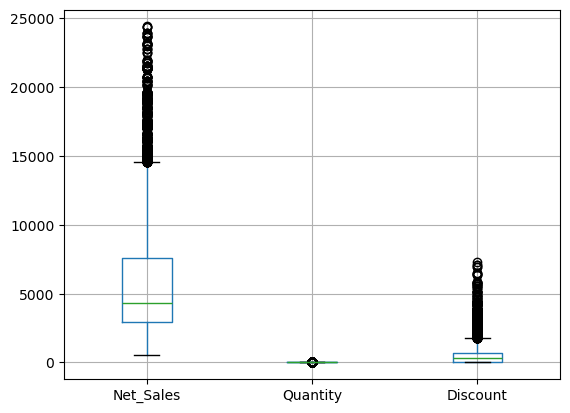

In [23]:
#Visual check using boxplots
orders[['Net_Sales', 'Quantity', 'Discount']].boxplot()
plt.show()

Here are the key insights from the boxplots:

*Net_Sales*                                                                         
High variability: The boxplot shows a very wide spread, meaning sales values differ greatly across orders.

Many outliers: Extreme values go up to ~25,000, suggesting some unusually large transactions.

Implication: Revenue is driven by a few very high-value orders, which could skew averages. Median values are much lower than the extremes.

*Quantity*                                                                                            
Tighter distribution: The range is much smaller compared to Net_Sales.

Fewer outliers: Most orders have similar quantities, with only a handful being unusually large.

Implication: Quantity per order is relatively consistent, so variability in sales is more likely due to price or discount factors rather than volume.

*Discount*                                                                                                           
Moderate spread: Discounts vary but not as wildly as Net_Sales.

Several outliers: Some orders received unusually high discounts.
= = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = 

Implication: Discounting practices are inconsistent. Outliers may represent special promotions or errors.
Revenue concentration risk: A small number of very large sales dominate Net_Sales. This could make the business vulnerable if those big customers stop ordering.

Stable order sizes: Quantity is predictable, which is good for inventory planning.

Discount strategy needs review: Outliers in discounts suggest either targeted promotions or irregular discounting that may need control


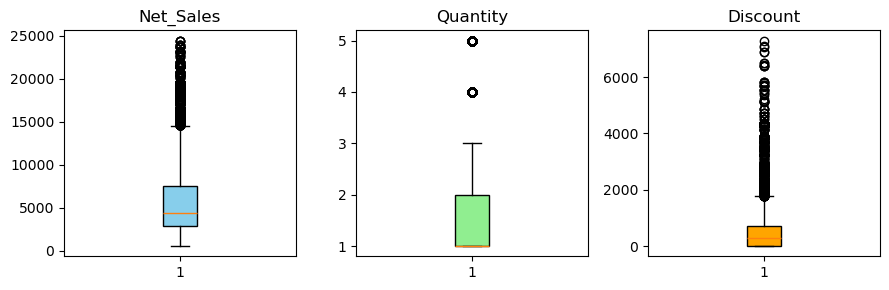

In [24]:
columns = ['Net_Sales', 'Quantity', 'Discount']
colors = ['skyblue', 'lightgreen', 'orange']

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, col, color in zip(axes, columns, colors):
    ax.boxplot(
        orders[col].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor=color)
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

**(vii) Groupby Analysis**

In [26]:
#Creating a master table by merging the 4 tables
master = (
    orders
    .merge(
        customers.drop(columns=['City']),
        on='Customer_ID',
        how='left'
    )
    .merge(
        products,
        on='Product_ID',
        how='left'
    )
    .merge(
        locations,
        on='City',
        how='left'
    )
)

display(master.head())

,Order_ID,Customer_ID,Product_ID,City,Order_Date,Quantity,Gross_Amount,Discount,Shipping_Fee,Order_Status,...,Signup_Date,Customer_Segment,Product_Name,Category,Unit_Price,In_Stock,Location_ID,State,Region,Market_Size
0,O000001,C03686,P0016,Bengaluru,2025-12-08,2,1858.0,278.7,0,Completed,...,2025-08-22,New,Storage Box,Home & Kitchen,50.0,Yes,L001,Karnataka,East,Medium
1,O000002,C01521,P0026,Chennai,2025-04-15,2,1584.0,316.8,100,Completed,...,2025-02-02,Premium,Cricket Bat,Sports,792.0,Yes,L005,Tamil Nadu,West,Medium
2,O000003,C01070,P0003,Delhi,2025-03-19,1,3441.0,688.2,100,Completed,...,2024-09-18,New,Bluetooth Speaker,Electronics,50.0,Yes,L003,Delhi,South,High
3,O000004,C01785,P0028,Mumbai,2025-09-20,4,9396.0,1409.4,100,Completed,...,2025-09-10,New,Dumbbells,Sports,2349.0,Yes,L002,Maharashtra,West,High
4,O000005,C02669,P0008,Hyderabad,2025-05-21,3,14181.0,1418.1,0,Completed,...,2023-03-05,Regular,Jeans,Fashion,50.0,Yes,L004,Telangana,West,High


In [27]:
#check on master table
print(master.columns.tolist())

['Order_ID', 'Customer_ID', 'Product_ID', 'City', 'Order_Date', 'Quantity', 'Gross_Amount', 'Discount', 'Shipping_Fee', 'Order_Status', 'Payment_Method', 'Net_Sales', 'Age', 'Gender', 'Signup_Date', 'Customer_Segment', 'Product_Name', 'Category', 'Unit_Price', 'In_Stock', 'Location_ID', 'State', 'Region', 'Market_Size']


In [28]:
#check for missing values in master table
master.isnull().sum()

Order_ID            0
Customer_ID         0
Product_ID          0
City                0
Order_Date          0
Quantity            0
Gross_Amount        0
Discount            0
Shipping_Fee        0
Order_Status        0
Payment_Method      0
Net_Sales           0
Age                 0
Gender              0
Signup_Date         0
Customer_Segment    0
Product_Name        0
Category            0
Unit_Price          0
In_Stock            0
Location_ID         0
State               0
Region              0
Market_Size         0
dtype: int64

**(a) Product Analysis**

In [29]:
product_analysis = master.groupby('Product_Name').agg(
    Total_Sales=('Net_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'count')
).sort_values('Total_Sales', ascending=False)

display(product_analysis)

,Total_Sales,Total_Quantity,Total_Orders
Product_Name,,,
Moisturizer,4977683.40,1181,648
Shampoo,4961336.00,1110,616
Football,4926794.40,1119,610
T-Shirt,4805905.00,1065,613
Coffee Maker,4601863.30,1056,586
Jeans,4573707.00,1051,567
Cookware Set,4384005.90,1093,624
Mixer Grinder,4242539.05,1068,594
Keyboard,4241812.90,1079,602


##### Product Analysis – Key Insights
- Moisturizer generated the highest total sales at approximately ₹49.78 lakh.
- Shampoo followed closely with approximately ₹49.61 lakh.
- Face Wash had the highest quantity sold (1,204) and the highest number of orders (663).
- Cricket Bat generated the lowest total sales, at approximately ₹8.61 lakh.
- Sneakers had the lowest number of orders (553).
- Sales and order volume are not always directly related. For example, Face Wash has the highest quantity and orders but is not the highest in total     sales.

Product-level analysis showed that Moisturizer generated the highest sales, while Face Wash recorded the highest quantity sold and number of orders. Cricket Bat had the lowest total sales, indicating significant variation in product-level revenue performance.


**(b) Category Analysis**

In [31]:
category_analysis = master.groupby('Category').agg(
    Total_Sales=('Net_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'count')
).sort_values('Total_Sales', ascending=False)

display(category_analysis)

,Total_Sales,Total_Quantity,Total_Orders
Category,,,
Beauty,23352136.75,6656,3695
Fashion,23003140.65,6372,3473
Electronics,19504133.50,6251,3510
Home & Kitchen,18709458.55,6550,3655
Sports,15882488.10,6652,3667


##### Category Analysis – Key Insights

- **Highest Sales:** Beauty – ₹2.34 crore
- **Second Highest Sales:** Fashion – ₹2.30 crore
- **Highest Orders:** Beauty – 3,695 orders
- **Lowest Sales:** Sports – ₹1.59 crore
- **Highest Quantity:** Beauty – 6,656 units
- **Key Observation:** Sales performance varies considerably across categories, with Beauty generating the highest revenue and Sports the lowest.

**(c) Customer Analysis**

In [33]:
customer_analysis = master.groupby('Customer_ID').agg(
    Total_Sales=('Net_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'count')
).sort_values('Total_Sales', ascending=False)

display(customer_analysis)

,Total_Sales,Total_Quantity,Total_Orders
Customer_ID,,,
C01258,106381.50,33,18
C00620,101709.35,28,13
C02617,90374.70,23,10
C02034,85436.40,24,12
C00622,83823.35,22,8
...,...,...,...
C03066,936.10,1,1
C03546,929.00,1,1
C02325,836.10,1,1


##### Customer Analysis – Key Insights

- **Highest Sales:** C01258 – ₹1,06,381.50
- **Second Highest Sales:** C00620 – ₹1,01,709.35
- **Highest Quantity Purchased:** C01258 – 33 units
- **Highest Number of Orders:** C01258 – 18 orders
- **Key Observation:** A small group of customers contributes significantly higher sales, while several customers have only one order and one unit purchased.
- **Lowest Sales:** C03926 – ₹554.40 among the displayed customers.

**(d) Location Analysis**

In [35]:
location_analysis = master.groupby('City').agg(
    Total_Sales=('Net_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'count')
).sort_values('Total_Sales', ascending=False)

display(location_analysis)

,Total_Sales,Total_Quantity,Total_Orders
City,,,
Mumbai,13614514.45,4442,2442
Chennai,13059700.10,4172,2281
Kolkata,12871309.55,4141,2307
Pune,12643208.65,4089,2279
Delhi,12324678.90,3991,2171
Hyderabad,12311928.40,3964,2181
Kochi,12132312.20,3925,2186
Bengaluru,11493705.30,3757,2153


##### Location Analysis – Key Insights

- **Highest Sales:** Mumbai – ₹1.36 crore
- **Second Highest Sales:** Chennai – ₹1.31 crore
- **Highest Quantity Sold:** Mumbai – 4,442 units
- **Highest Number of Orders:** Mumbai – 2,442 orders
- **Lowest Sales:** Bengaluru – ₹1.15 crore
- **Lowest Quantity Sold:** Bengaluru – 3,757 units
- **Lowest Number of Orders:** Bengaluru – 2,153 orders
- **Key Observation:** Mumbai has the highest sales, quantity, and number of orders, while Bengaluru records the lowest values across all three measures.

**(viii) Relationships between important numerical variables**

In [36]:
numerical_cols = [
    'Age',
    'Quantity',
    'Gross_Amount',
    'Discount',
    'Shipping_Fee',
    'Net_Sales',
    'Unit_Price'
]

correlation = master[numerical_cols].corr()

display(correlation)

,Age,Quantity,Gross_Amount,Discount,Shipping_Fee,Net_Sales,Unit_Price
Age,1.000000,0.006928,0.003986,0.008759,-0.009181,0.002600,0.000547
Quantity,0.006928,1.000000,0.824549,0.423508,0.007742,0.813150,-0.006551
Gross_Amount,0.003986,0.824549,1.000000,0.508717,0.008091,0.987076,0.314675
Discount,0.008759,0.423508,0.508717,1.000000,0.006208,0.364398,0.150617
Shipping_Fee,-0.009181,0.007742,0.008091,0.006208,1.000000,0.016664,-0.003922
Net_Sales,0.002600,0.813150,0.987076,0.364398,0.016664,1.000000,0.312308
Unit_Price,0.000547,-0.006551,0.314675,0.150617,-0.003922,0.312308,1.000000


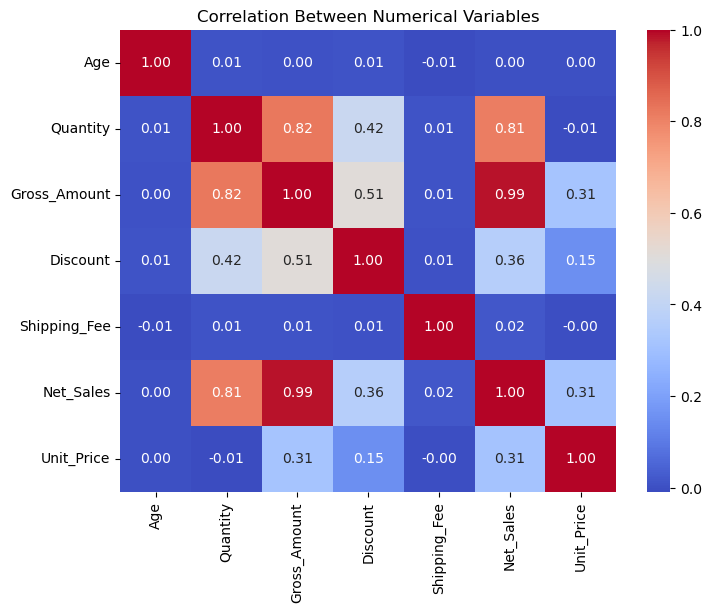

In [37]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Variables')
plt.show()

##### Relationship Analysis – Key Insights

- **Gross Amount and Net Sales (0.99):** Very strong positive relationship.
- **Quantity and Gross Amount (0.82):** Strong positive relationship.
- **Quantity and Net Sales (0.81):** Strong positive relationship.
- **Discount and Gross Amount (0.51):** Moderate positive relationship.
- **Discount and Quantity (0.42):** Moderate positive relationship.
- **Discount and Net Sales (0.36):** Weak-to-moderate positive relationship.
- **Unit Price and Net Sales (0.31):** Weak-to-moderate positive relationship.
- **Age and Net Sales (0.00):** No meaningful linear relationship.
- **Shipping Fee and Net Sales (0.02):** Almost no linear relationship.

**Overall Observation:** Gross Amount and Quantity have the strongest relationships with Net Sales, while Age and Shipping Fee show almost no linear relationship with Net Sales.

One important point: correlation shows association, not causation. For example, the 0.99 correlation between Gross Amount and Net Sales is expected to be very high because these values are directly related through the sales calculation

### Scatter plots for important relationships

**(a) Quantity vs Net Sales**

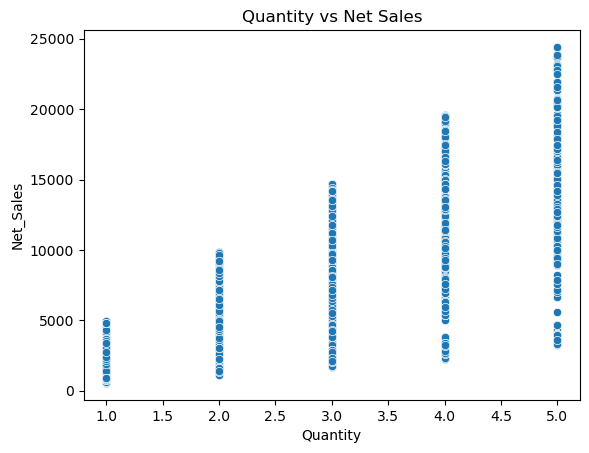

In [38]:
sns.scatterplot(data=master, x='Quantity', y='Net_Sales')
plt.title('Quantity vs Net Sales')
plt.show()

**(b) Gross Amount vs Net Sales**

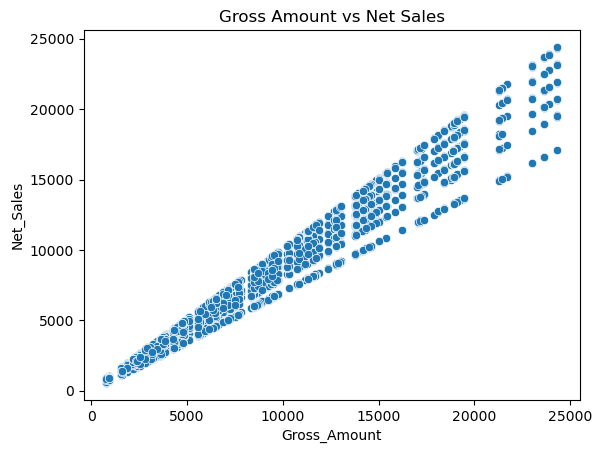

In [39]:
sns.scatterplot(data=master, x='Gross_Amount', y='Net_Sales')
plt.title('Gross Amount vs Net Sales')
plt.show()

**(c) Discount vs Net Sales**

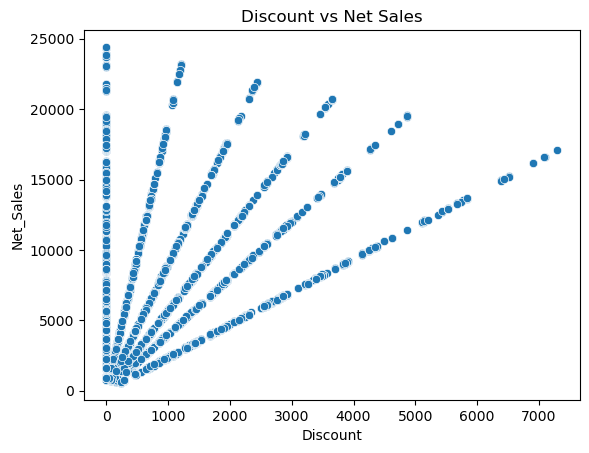

In [41]:
sns.scatterplot(data=master, x='Discount', y='Net_Sales')
plt.title('Discount vs Net Sales')
plt.show()

**(d) Unit Price vs Net Sales**

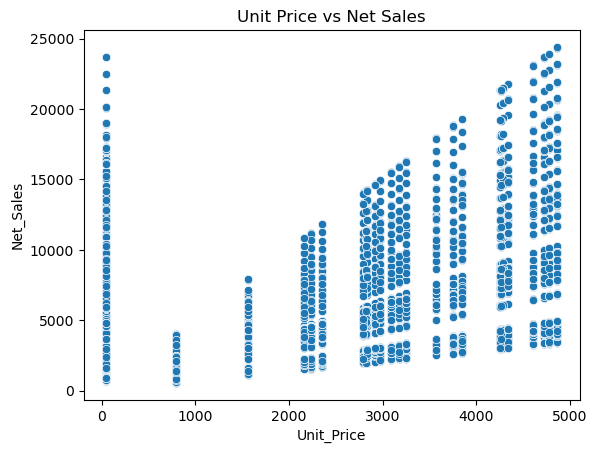

In [42]:
sns.scatterplot(data=master, x='Unit_Price', y='Net_Sales')
plt.title('Unit Price vs Net Sales')
plt.show()

**(ix) Visual Analysis**

**(a) Monthly Sales Trend**

Order_Date
2025-01    8814841.75
2025-02    7435190.55
2025-03    8468396.30
2025-04    7934521.75
2025-05    8637992.65
2025-06    8204109.20
2025-07    8759777.05
2025-08    8400279.65
2025-09    8682143.50
2025-10    8319585.30
2025-11    8678317.00
2025-12    8116202.85
Freq: M, Name: Net_Sales, dtype: float64

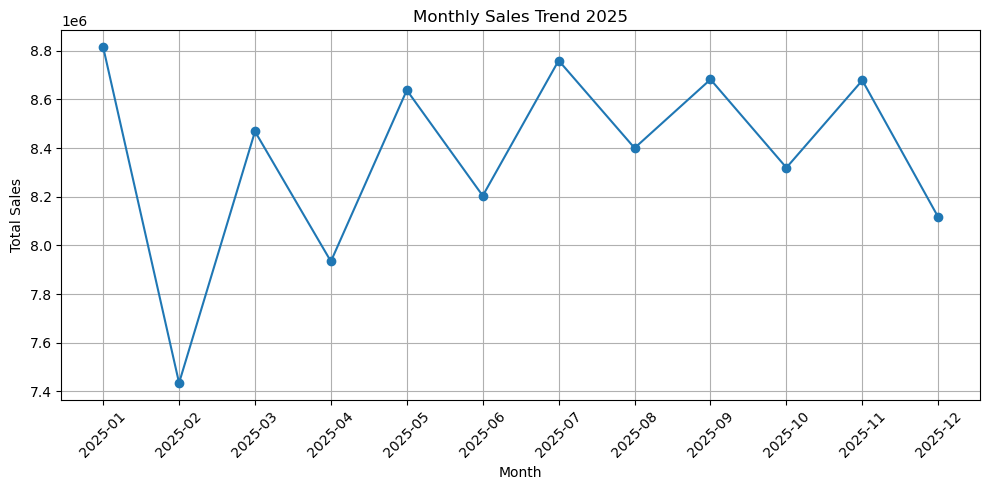

In [49]:
# Convert Order_Date to datetime
master['Order_Date'] = pd.to_datetime(master['Order_Date'])

# Calculate monthly sales
monthly_sales = master.groupby(
    master['Order_Date'].dt.to_period('M')
)['Net_Sales'].sum()
display(monthly_sales)
# Plot
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend 2025')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

##### Monthly Sales Trend – Key Insights

- **Highest Sales:** January 2025 – ₹88.15 lakh
- **Lowest Sales:** February 2025 – ₹74.35 lakh
- Sales dropped sharply from January to February and recovered in March.
- Sales remained relatively stable between ₹79 lakh and ₹88 lakh during most months.
- **July 2025** recorded another high sales value of ₹87.60 lakh.
- **Overall Observation:** Monthly sales fluctuated throughout 2025 without a consistent upward or downward trend.

**(b) Sales by product category**

In [50]:
category_sales = master.groupby('Category')['Net_Sales'].sum().sort_values(ascending=False)

display(category_sales)

Category
Beauty            23352136.75
Fashion           23003140.65
Electronics       19504133.50
Home & Kitchen    18709458.55
Sports            15882488.10
Name: Net_Sales, dtype: float64

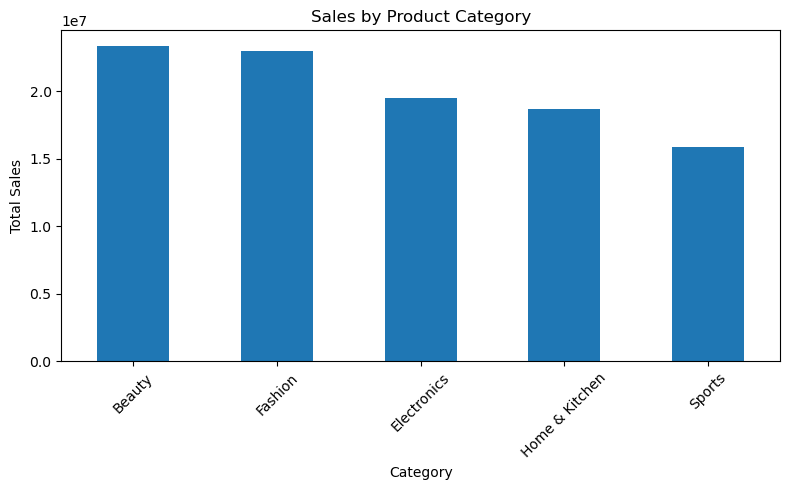

In [51]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### Sales by Product Category – Key Insights

- **Highest Sales:** Beauty – ₹2.34 crore
- **Second Highest:** Fashion – ₹2.30 crore
- **Lowest Sales:** Sports – ₹1.59 crore
- **Overall Observation:** Beauty and Fashion generated the highest sales, while Sports recorded the lowest sales among the categories.

**(c) Top products by sales**

In [54]:
top_products = (
    master.groupby('Product_Name')['Net_Sales']
    .sum()
    .sort_values(ascending=False)
)
top_10_products = top_products.head(10)

display(top_10_products)

Product_Name
Moisturizer      4977683.40
Shampoo          4961336.00
Football         4926794.40
T-Shirt          4805905.00
Coffee Maker     4601863.30
Jeans            4573707.00
Cookware Set     4384005.90
Mixer Grinder    4242539.05
Keyboard         4241812.90
Face Wash        4199567.50
Name: Net_Sales, dtype: float64

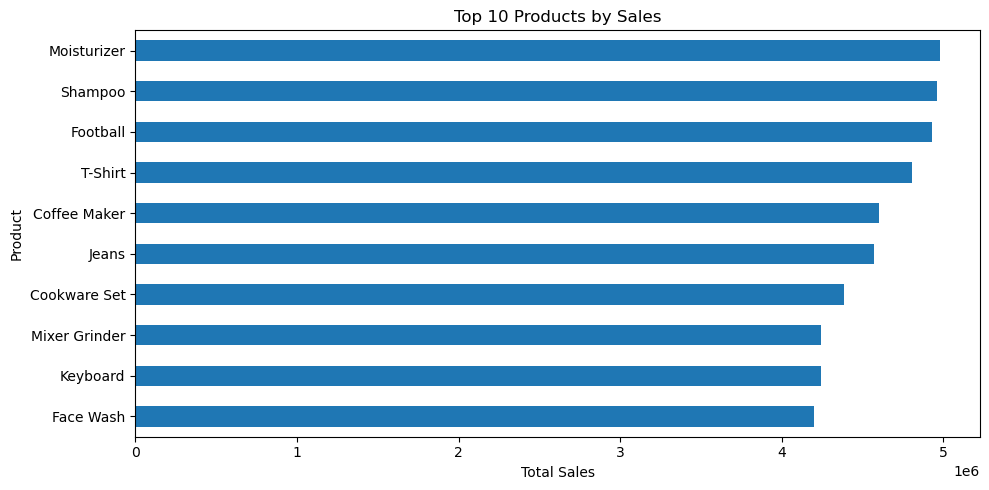

In [59]:
plt.figure(figsize=(10, 5))

top_10_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

##### Top Products by Sales – Key Insights

- **Top Product:** Moisturizer – ₹49.78 lakh
- **Second:** Shampoo – ₹49.61 lakh
- **Third:** Football – ₹49.27 lakh
- **Top 10 products** generated sales ranging from approximately ₹42 lakh to ₹49.78 lakh.
- **Overall Observation:** Moisturizer generated the highest sales among all products.

**(d) Sales by customer segment**

In [62]:
#Calculate sales by customer segment
segment_sales = (
    master.groupby('Customer_Segment')['Net_Sales']
    .sum()
    .sort_values(ascending=False)
)

display(segment_sales)

Customer_Segment
Regular    50573637.30
New        35681577.20
Premium    14196143.05
Name: Net_Sales, dtype: float64

<Figure size 700x500 with 0 Axes>

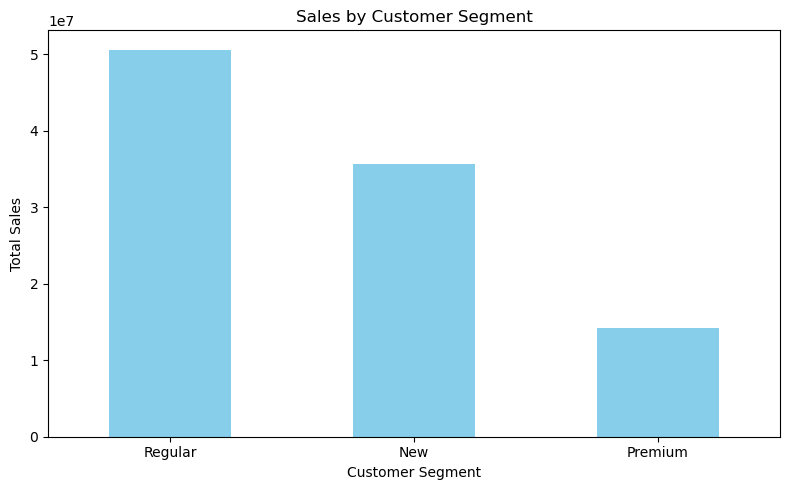

In [63]:
plt.figure(figsize=(8, 5))

segment_sales.plot(
    kind='bar',
    color='skyblue'
)

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

##### Sales by Customer Segment – Key Insights

- **Highest Sales:** Regular – ₹5.06 crore
- **Second Highest Sales:** New – ₹3.57 crore
- **Lowest Sales:** Premium – ₹1.42 crore
- **Overall Observation:** Regular customers generated the highest sales, while Premium customers recorded the lowest sales.

**(e) Sales by Location**

In [64]:
location_sales = (
    master.groupby('City')['Net_Sales']
    .sum()
    .sort_values(ascending=False)
)

display(location_sales)

City
Mumbai       13614514.45
Chennai      13059700.10
Kolkata      12871309.55
Pune         12643208.65
Delhi        12324678.90
Hyderabad    12311928.40
Kochi        12132312.20
Bengaluru    11493705.30
Name: Net_Sales, dtype: float64

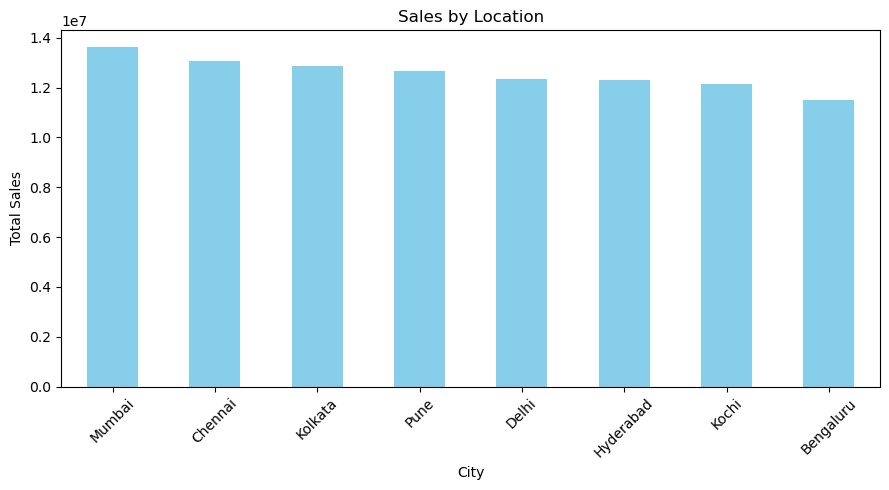

In [65]:
plt.figure(figsize=(9, 5))

location_sales.plot(
    kind='bar',
    color='skyblue'
)

plt.title('Sales by Location')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### Sales by Location – Key Insights

- **Highest Sales:** Mumbai – ₹1.36 crore
- **Second Highest Sales:** Chennai – ₹1.31 crore
- **Lowest Sales:** Bengaluru – ₹1.15 crore
- **Highest Quantity Sold:** Mumbai – 4,442 units
- **Highest Number of Orders:** Mumbai – 2,442 orders
- **Overall Observation:** Mumbai recorded the highest sales, quantity sold, and number of orders, while Bengaluru recorded the lowest values.

**(f) Discount impact on sales/order value**

In [68]:
#Calculate Discount Percentage
master['Discount_Pct'] = (
    master['Discount'] / master['Gross_Amount'] * 100
)
display(master[['Gross_Amount', 'Discount', 'Discount_Pct', 'Net_Sales']].head())

,Gross_Amount,Discount,Discount_Pct,Net_Sales
0,1858.0,278.7,15.0,1579.3
1,1584.0,316.8,20.0,1367.2
2,3441.0,688.2,20.0,2852.8
3,9396.0,1409.4,15.0,8086.6
4,14181.0,1418.1,10.0,12762.9


In [69]:
#Calculate Average Order Value (AOV)
master['Order_Value'] = master['Net_Sales']

aov = master['Order_Value'].mean()

print("Average Order Value:", aov)

Average Order Value: 5580.630975000001


In [70]:
#Compare discount with sales and order value
discount_impact = master.groupby('Discount_Pct').agg(
    Total_Sales=('Net_Sales', 'sum'),
    Average_Order_Value=('Order_Value', 'mean'),
    Number_of_Orders=('Order_ID', 'count')
)

display(discount_impact)

,Total_Sales,Average_Order_Value,Number_of_Orders
Discount_Pct,,,
0.0,38069785.00,5971.730980,6375
5.0,15519641.25,5858.679219,2649
10.0,21672986.50,5472.976389,3960
15.0,11749291.30,5290.090635,2221
15.0,2508815.70,5270.621218,476
20.0,6995062.40,4867.823521,1437
30.0,3291012.90,4520.622115,728
30.0,644762.50,4186.769481,154


In [71]:
#Create Discount Categories
master['Discount_Range'] = pd.cut(
    master['Discount_Pct'],
    bins=[-1, 5, 10, 20, 30, 100],
    labels=['0-5%', '5-10%', '10-20%', '20-30%', '30%+']
)
discount_impact = master.groupby('Discount_Range', observed=True).agg(
    Total_Sales=('Net_Sales', 'sum'),
    Average_Order_Value=('Order_Value', 'mean'),
    Number_of_Orders=('Order_ID', 'count')
)

display(discount_impact)

,Total_Sales,Average_Order_Value,Number_of_Orders
Discount_Range,,,
0-5%,53589426.25,5938.544576,9024
5-10%,21672986.50,5472.976389,3960
10-20%,21253169.40,5141.066618,4134
20-30%,3291012.90,4520.622115,728
30%+,644762.50,4186.769481,154


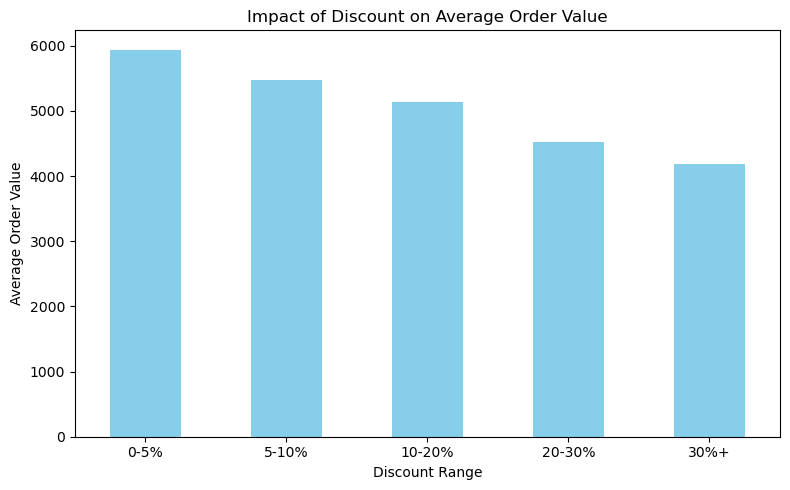

In [72]:
plt.figure(figsize=(8, 5))

discount_impact['Average_Order_Value'].plot(
    kind='bar',
    color='skyblue'
)

plt.title('Impact of Discount on Average Order Value')
plt.xlabel('Discount Range')
plt.ylabel('Average Order Value')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

##### Discount Impact on Average Order Value – Key Insights

- **Highest AOV:** 0–5% discount – approximately ₹5,900
- **Lowest AOV:** 30%+ discount – approximately ₹4,200
- **Overall Observation:** Average order value decreases as the discount percentage increases.